# Sprint 3 · Semana 8: búsqueda de hiperparámetros con *pruning*, artefactos y curva de aprendizaje

Tesis: Detección Automatizada y Priorización de Eventos Adversos en Notas Clínicas mediante un Flujo de Procesamiento (Pipeline) de NLP y Aprendizaje Automático — Aplicación de la Matriz de Priorización del Modelo GEMSES sobre MIMIC-IV

Autor: Carlos Pérez Pérez · Curso: MIA-14 Trabajo de Investigación II · Docente: Glen Rodríguez · 4 de noviembre de 2026

El presente cuaderno reúne el entregable de la semana 8, el cual completa la búsqueda de hiperparámetros de la semana 7 con lo que pide la
lámina 21 del material de esa semana y se entrega en la rama `sprint3-hiperparametros-pruning`. Se trata de experimentos comparables entre
la búsqueda aleatoria y la bayesiana con *pruning*, de registros y artefactos guardados, de una tabla *top-k* con un gráfico de evolución y del
resumen del espacio, el presupuesto y la decisión.

El cuaderno no vuelve a entrenar el modelo, dado que solo las búsquedas sumaron 2.0 horas de cálculo, sino que lee los resultados que deja el *script*
`src/experimentos_hp_pruning.py` en `reportes/` y en `logs/`. De esta manera, cada cifra del texto puede verificarse en las celdas de código
sin acceso a los datos de MIMIC-IV, protegidos por el acuerdo de uso de PhysioNet.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import figuras_hp_pruning as fhp  # mismas funciones que dibujan reportes/figuras/fig_hp_pruning_*.png

leer = lambda p: json.loads((RAIZ / p).read_text(encoding="utf-8"))
R, R7 = leer("reportes/hp_pruning_resultados.json"), leer("reportes/hp_resultados.json")
ens = pd.read_csv(RAIZ / "reportes" / "hp_pruning_ensayos.csv", keep_default_na=False, na_values=[""])
ens["reutilizado_de"] = ens.reutilizado_de.fillna("")
s7 = pd.read_csv(RAIZ / "reportes" / "hp_ensayos.csv", keep_default_na=False, float_precision="round_trip")
topk = pd.read_csv(RAIZ / "reportes" / "hp_pruning_topk.csv", keep_default_na=False)
curva = pd.read_csv(RAIZ / "reportes" / "hp_pruning_curva.csv")
runs = pd.read_csv(RAIZ / "logs" / "hpo_runs.csv", keep_default_na=False)
plt.rcParams.update({"font.size": 9})
print("Resultados leídos:", R["generado"], "· semilla", R["semilla"], "· Optuna", R["optuna"], "· scikit-learn", R["sklearn"],
      "· decisión:", R["decision"], "· esta corrida:", round(R["tiempos_segundos"]["esta_corrida"] / 60, 1), "min ·",
      "folds tomados de la caché (búsqueda y configuración actual):", R["folds_de_corridas_previas"])

Resultados leídos: 2026-11-04T14:42:35 · semilla 42 · Optuna 5.0.0 · scikit-learn 1.7.2 · decisión: se adopta la candidata · esta corrida: 64.3 min · folds tomados de la caché (búsqueda y configuración actual): 105


## 1. Lo que pide el entregable y dónde se responde

La lámina 21 del material de la semana 7 (Rodríguez, 2026) fija cuatro requisitos para el entregable de esta semana, y las láminas 13, 15, 16
y 20 detallan cómo cumplirlos. Como se aprecia en la Tabla 1, cada requisito tiene una sección de este cuaderno que lo responde.

Tabla 1. Requisitos del entregable y sección del cuaderno que los responde

| Requisito (lámina) | Detalle en el material | Sección |
|---|---|---|
| Experimentos comparables aleatoria y bayesiana con *pruning* o *early stopping* (21) | Presupuesto de 30 a 100 ensayos, tiempo máximo por ensayo y total, semillas y particiones fijas (13); registrar el número de iteraciones (15) | 2, 3 y 5 |
| *Logs* y artefactos guardados (21) | `logs/hpo_runs.csv` con identificador, parámetros, semilla, partición, media, desviación y tiempo; el mejor modelo de cada ensayo, la curva de entrenamiento y la configuración; comando único en el README (16) | 8 y 9 |
| Tabla *top-k* y gráfico de evolución (21) | *Top-k* con ensayo, parámetros, métrica media ± desviación, tiempo y notas; métrica por ensayo e importancia de los hiperparámetros (20) | 4 y 6 |
| Resumen del espacio, el presupuesto y la decisión (21) | Configuración ganadora y 1 o 2 de respaldo (20) | 2 y 7 |

Fuente: elaboración propia a partir del material de la semana 7 (Rodríguez, 2026).

## 2. Diseño de la semana 8, fijado antes de correr

El modelo, los datos y la partición no cambiaron respecto de la semana 7. Se trata de la configuración A+B+C, es decir, las palabras de la
epicrisis (A), los pares de palabras consecutivas (B) y las variables de la hospitalización con el largo de la nota (C). Estos atributos
alimentan una regresión logística entrenada con las filas de la variante D2. El espacio de búsqueda es el mismo de la semana 7, con siete hiperparámetros,
dentro del máximo de seis a ocho que recomienda la lámina 5, y con C en escala logarítmica. Cada configuración se evalúa con
`StratifiedGroupKFold` de 3 *folds* por paciente y semilla 42, en las epicrisis de validación sin
etiqueta dudosa.

El *pruning*, también denominado poda de ensayos, consiste en detener un ensayo antes de terminarlo cuando sus resultados intermedios ya
indican que no competirá con los mejores. A criterio del autor, la forma que corresponde a una regresión logística es el corte por *fold*,
dado que este modelo no tiene el *early stopping* nativo que la lámina 13 asocia a XGBoost, LightGBM y redes neuronales.

Por ello, cada ensayo se evaluó *fold* por *fold*, y después de cada uno informó a Optuna la PR-AUC media de los *folds* ya evaluados. El
`MedianPruner` de Optuna corta el ensayo si su mejor valor intermedio queda por debajo de la mediana de los ensayos completos de la misma
búsqueda en ese *fold* (Optuna, s. f.-a). Como se aprecia en la Tabla 2, el resto del diseño amplía el presupuesto de la semana 7 hasta el
mínimo que fija la lámina 13. Como sugiere la lámina 9, el diseño se documentó en un archivo de configuración, `config/config.yaml`, el
cual quedó en un *commit* anterior a la corrida.

Tabla 2. Presupuesto y criterio de parada de las búsquedas de las semanas 7 y 8

| Elemento | Semana 7 | Semana 8 |
|---|---|---|
| Ensayos por método | 15 | 30 |
| Ensayos al azar antes del TPE | 5 | 10 (la lámina 7 sugiere de 10 a 20) |
| *Pruning* | no | `MedianPruner`, desde el primer *fold*, una vez que la búsqueda tiene 5 ensayos completos |
| Tiempo máximo por ensayo | sin límite | 600 s, revisado después de cada *fold* |
| Tiempo máximo por búsqueda | sin límite | 240 min |
| Número de iteraciones de la regresión | no se registró | se registra en cada *fold* |
| Regla de decisión | la candidata reemplaza a la actual si la supera en al menos 4 de 5 *folds* y la mejora media supera 1 desviación estándar | la misma |
| *Test* | medición de la actual y de la candidata | medición de la actual y de la candidata, solo si la regla adopta la candidata |
| Respaldo | no se definió | las 2 de mayor PR-AUC media en 3 *folds*, distintas de la ganadora, entre las semanas 7 y 8 |

Fuente: elaboración propia a partir de `config/config.yaml` (secciones `hiperparametros` e `hiperparametros_pruning`).

Con la misma semilla, los 15 primeros ensayos de la búsqueda aleatoria repiten las configuraciones de la semana 7, lo cual permite medir
el efecto del *pruning* sobre los mismos ensayos. Asimismo, los 10 primeros ensayos de la bayesiana coinciden con los 10 primeros de la
aleatoria, de modo que se evaluaron una sola vez y se reutilizaron, igual que en la semana 7.

In [2]:
H8 = R["parametros"]
print("Presupuesto:", H8["n_ensayos"], "ensayos por método ·", H8["ensayos_iniciales_tpe"], "al azar antes del TPE · pruner", H8["pruner"])
print("Límites:", H8["max_segundos_por_ensayo"], "s por ensayo ·", H8["max_minutos_por_busqueda"], "min por búsqueda · respaldo:", H8["n_respaldo"])
print("Espacio:", R["espacio"])

Presupuesto: 30 ensayos por método · 10 al azar antes del TPE · pruner {'n_startup_trials': 5, 'n_warmup_steps': 0, 'interval_steps': 1}
Límites: 600 s por ensayo · 240 min por búsqueda · respaldo: 2
Espacio: {'C': [0.001, 100.0], 'A_max_features': [10000, 20000, 40000, 60000], 'A_min_df': [2, 3, 5], 'B_max_features': [10000, 20000, 40000], 'B_min_df': [2, 3, 5], 'class_weight': ['balanced', 'ninguno'], 'sublinear_tf': [True, False]}


## 3. Controles de reproducción

Antes de comparar, se comprobó que la corrida de la semana 8 parte del mismo punto que la de la semana 7. La configuración actual, medida
*fold* por *fold* en los mismos 3 *folds*, obtuvo una PR-AUC media de 0.8498, con una diferencia máxima por *fold* de
0 frente a la semana 7. Asimismo, los 15 primeros ensayos de la aleatoria repitieron las configuraciones de la semana 7, y sus *folds* evaluados reproducen los de esa semana, con una diferencia máxima de 0.
En consecuencia, las diferencias que siguen se deben al *pruning* y al presupuesto, y no a un cambio en los datos o en el cálculo.

In [3]:
print("Referencia (actual) frente a la semana 7:", R["control_referencia_semana7"])
e = R["efecto_pruning_mismos_ensayos"]
print("Mismas configuraciones que la semana 7:", e["mismas_configuraciones_que_la_semana_7"], "· diferencia máxima por fold:",
      e["dif_maxima_pr_auc_por_fold"], "· reproduce:", e["reproduce_folds"])

Referencia (actual) frente a la semana 7: {'pr_auc_semana7': [0.848753, 0.850137, 0.850421], 'pr_auc_esta_corrida': [0.848753, 0.850137, 0.850421], 'dif_maxima': 0.0, 'reproduce': True}
Mismas configuraciones que la semana 7: True · diferencia máxima por fold: 0.0 · reproduce: True


La corrida comenzó el 2 de noviembre y su *log*, `logs/experimentos_hp_pruning_20261102_131402.log`, termina a las 21:59:48, después de 8.8 horas, con el control de la curva de aprendizaje. Hasta ese momento había hecho las dos búsquedas, la confirmación, el *test*, el respaldo y la curva, de modo que se detuvo al comenzar el último paso, el de los modelos. El registro de eventos de Windows del equipo anota un reinicio a las 22:01 (eventos 109, 6006 y 6005) y ningún apagado inesperado. A criterio del autor, ese reinicio detuvo la corrida, dado que el *log* termina poco antes. En ese *log*, un paso de la curva (*fold* 3, fracción 0.5) figura con 19 335 s, dado que coincidió con una suspensión del equipo entre las 16:06 y las 21:26, que consta en el mismo registro de eventos.

La corrida se retomó el 4 de noviembre de 2026 con el mismo diseño y con el *script* corregido en la lectura de C, como se explica más adelante. Además, parte de su código se reorganizó en funciones, y el *script* se probó con `--prueba` antes de retomar la corrida (`logs/experimentos_hp_pruning_prueba_20261104_133609.log`). El *script* tomó de la caché los *folds* ya calculados de la búsqueda, con su tiempo original, y las confirmaciones con 5 *folds*. Luego calculó de nuevo el *test* y la curva, y por primera vez los modelos, como consta en `logs/experimentos_hp_pruning_20261104_133819.log`. Como se aprecia en la salida siguiente, los 60 ensayos, la regla, el *test*, el respaldo y la curva coinciden con los del 2 de noviembre.

In [4]:
import ast
import re
from datetime import datetime

import numpy as np


def leer_log0(texto):
    hora = lambda s: datetime.strptime(s[:19], "%Y-%m-%d %H:%M:%S")
    lineas = texto.splitlines()
    ens0 = pd.DataFrame(re.findall(r"\| INFO \| (aleatoria|bayesiana) #(\d+) · .*? · (completo|cortado por pruning|cortado por tiempo) "
                                   r"tras (\d) fold\(s\) · PR-AUC ([\d.]+) · (\d+) s", texto),
                        columns=["metodo", "ensayo", "estado", "folds", "pr_auc", "segundos"]).astype(
        {"ensayo": int, "folds": int, "pr_auc": float, "segundos": int})
    cur0 = pd.DataFrame(re.findall(r"curva de aprendizaje · fold (\d) · fracción ([\d.]+) \(([\d,]+) filas\) · PR-AUC entrenamiento "
                                   r"([\d.]+) · validación ([\d.]+) · (\d+) s", texto),
                        columns=["fold", "fraccion", "filas", "tr", "va", "segundos"])
    cur0 = cur0.assign(fold=cur0.fold.astype(int), fraccion=cur0.fraccion.astype(float), filas=cur0.filas.str.replace(",", "").astype(int),
                       tr=cur0.tr.astype(float), va=cur0.va.astype(float), segundos=cur0.segundos.astype(int))
    dic = lambda patron: ast.literal_eval(re.search(patron, texto, re.M).group(1))
    return {"inicio": hora(lineas[0]), "fin": hora(lineas[-1]), "ensayos": ens0, "curva": cur0,
            "reloj": {m: int(s) for m, s in re.findall(r"búsqueda (aleatoria|bayesiana): \d+ ensayos · .*? · (\d+) s de reloj", texto)},
            "test": {m: dic(rf"TEST {m}: (\{{.*\}})$") for m in ("actual", "candidata")},
            "regla": dic(r"confirmación \(5 folds\): .*? · regla: (\{.*?\})(?: · .*)?$"),
            "respaldo": re.findall(r"\| INFO \| respaldo \d: (semana \d · (?:aleatoria|bayesiana) #\d+) ·", texto),
            "efecto": dic(r"mismas configuraciones que la semana 7\): (\{.*\})$"),
            "importancia": dic(r"importancia de los hiperparámetros: (\{.*\})$")}


def comparar_log0(L0, ens, curva, test, regla, respaldo):
    e = ens.assign(pr=ens.pr_auc_media.round(4)).merge(L0["ensayos"], on=["metodo", "ensayo"], how="outer", indicator=True)
    c = curva.merge(L0["curva"], on=["fold", "fraccion"], how="outer", indicator=True)
    return {"n_ensayos": int(len(L0["ensayos"])),
            "regla_igual": all(regla[k] == v for k, v in L0["regla"].items()),
            "respaldo_igual": [r["origen"] for r in respaldo] == L0["respaldo"],
            "ensayos_iguales": bool((e._merge == "both").all() and (e.estado_x == e.estado_y).all()
                                    and (e.folds_evaluados == e.folds).all() and np.allclose(e.pr, e.pr_auc, rtol=0, atol=1e-9)),
            "tiempos_iguales": bool((e._merge == "both").all() and (e.segundos_x.round(0) == e.segundos_y).all()),
            "test_igual": test is not None and test == L0["test"],
            "curva_igual": bool((c._merge == "both").all() and (c.filas_entrenamiento == c.filas).all()
                                and np.allclose(c.pr_auc_entrenamiento.round(4), c.tr, rtol=0, atol=1e-9)
                                and np.allclose(c.pr_auc_validacion.round(4), c.va, rtol=0, atol=1e-9))}


L0 = leer_log0((RAIZ / "logs/experimentos_hp_pruning_20261102_131402.log").read_text(encoding="utf-8"))
print("Corrida del 2 de noviembre:", L0["inicio"], "a", L0["fin"], "· reloj de las búsquedas (s):", L0["reloj"])
paso = L0["curva"].loc[L0["curva"].segundos.idxmax()].to_dict()
print("Paso más largo de la curva en ese log:", {k: int(v) if k in ("fold", "filas", "segundos") else v for k, v in paso.items()})
print("Coincidencias con la corrida retomada:", comparar_log0(L0, ens, curva, R["test"], R["regla"], R["respaldo"]))
print("El 2 de noviembre, mismas configuraciones que la semana 7:", L0["efecto"]["mismas_configuraciones_que_la_semana_7"],
      "· configuraciones distintas:", L0["importancia"]["n_configuraciones"])

Corrida del 2 de noviembre: 2026-11-02 13:14:02 a 2026-11-02 21:59:48 · reloj de las búsquedas (s): {'aleatoria': 4233, 'bayesiana': 3053}
Paso más largo de la curva en ese log: {'fold': 3, 'fraccion': 0.5, 'filas': 19657, 'tr': 0.9775, 'va': 0.8379, 'segundos': 19335}
Coincidencias con la corrida retomada: {'n_ensayos': 60, 'regla_igual': True, 'respaldo_igual': True, 'ensayos_iguales': True, 'tiempos_iguales': True, 'test_igual': True, 'curva_igual': True}
El 2 de noviembre, mismas configuraciones que la semana 7: False · configuraciones distintas: 46


Asimismo, en el *log* del 2 de noviembre el control de las mismas configuraciones dio falso, y la importancia contó 46 configuraciones distintas en lugar de 43. La causa fue la lectura de C en `reportes/hp_ensayos.csv`, cuyo último dígito cambiaba con el lector por defecto de pandas, de modo que algunas configuraciones de la semana 7 no se reconocían como iguales a las mismas de la semana 8. Se corrigió con una lectura exacta antes de retomar la corrida, y la corrección cambió ese control y la importancia de los hiperparámetros, pero no los ensayos, la decisión, el *test* ni el respaldo.

## 4. Resultados de la búsqueda: evolución y tabla *top-k*

Figura 1. Mejor resultado acumulado de cada búsqueda y resultado de cada ensayo de la semana 8

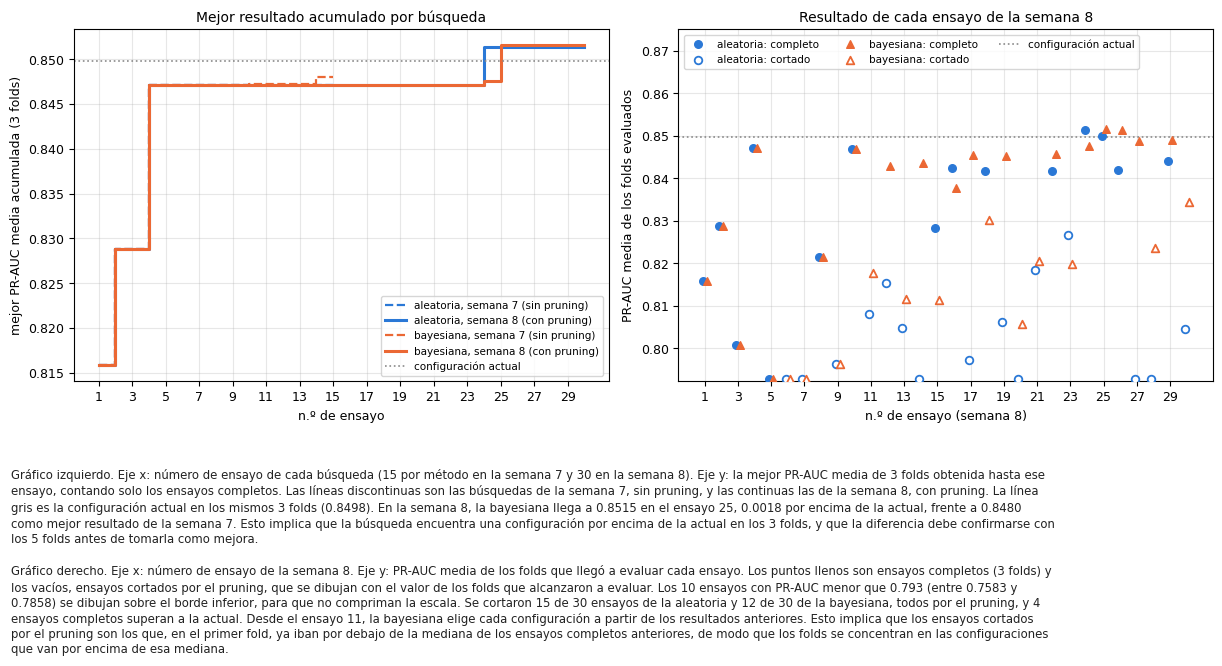

In [5]:
fig = fhp.fig_evolucion(R, ens, s7); plt.show()

Fuente: elaboración propia a partir de `reportes/hp_pruning_ensayos.csv` y `reportes/hp_ensayos.csv`. Las diferencias se calculan con los valores sin redondear.

Como se aprecia en la Figura 1, la mejor configuración completa de la semana 8 salió de la búsqueda bayesiana, en el ensayo
25, con una PR-AUC media de 0.8515, es decir, 0.0018
por encima de la configuración actual en los mismos 3 *folds* (0.8498). El mejor
resultado de la semana 7 había sido 0.8480. Asimismo, 4 ensayos completos superan a la actual en los 3 *folds* y, como se fijó antes de correr, la mejor configuración debe confirmarse con los 5 *folds* (sección 7).

Tabla 3. Las 10 configuraciones con mayor PR-AUC media en 3 *folds* (ensayos completos de las semanas 7 y 8 y la configuración actual)

In [6]:
t = topk.head(10).copy()
t["PR-AUC media ± desv."] = t.pr_auc_media.map("{:.4f}".format) + " ± " + t.pr_auc_std.map("{:.4f}".format)
t["notas"] = (t.rol + t.tambien_en.map(lambda s: f" (también {s})" if s else "")).str.strip(" ")
display(t[["puesto", "origen", "parametros", "PR-AUC media ± desv.", "segundos", "notas"]]
        .rename(columns={"origen": "ensayo", "parametros": "hiperparámetros", "segundos": "tiempo (s)"})
        .style.format({"tiempo (s)": "{:.0f}"}).hide(axis="index"))

puesto,ensayo,hiperparámetros,PR-AUC media ± desv.,tiempo (s),notas
1,semana 8 · bayesiana #25,C=1.873 · A 60000/3 · B 40000/5 · class_weight=ninguno · sublinear_tf=True,0.8515 ± 0.0006,291,ganadora
2,semana 8 · aleatoria #24,C=1.443 · A 60000/3 · B 20000/5 · class_weight=balanced · sublinear_tf=False,0.8514 ± 0.0021,233,respaldo 1
3,semana 8 · bayesiana #26,C=1.506 · A 10000/3 · B 40000/5 · class_weight=ninguno · sublinear_tf=True,0.8513 ± 0.0009,224,respaldo 2
4,semana 8 · aleatoria #25,C=1.233 · A 40000/2 · B 20000/5 · class_weight=balanced · sublinear_tf=True,0.8500 ± 0.0008,216,
5,"configuración actual (referencia, fuera del presupuesto)",C=1 · A 20000/3 · B 20000/3 · class_weight=balanced · sublinear_tf=True,0.8498 ± 0.0009,176,
6,semana 8 · bayesiana #27,C=0.6522 · A 60000/3 · B 40000/5 · class_weight=ninguno · sublinear_tf=True,0.8489 ± 0.0011,166,
7,semana 8 · bayesiana #29,C=3.38 · A 60000/2 · B 40000/5 · class_weight=ninguno · sublinear_tf=True,0.8489 ± 0.0004,328,
8,semana 7 · bayesiana #14,C=2.318 · A 10000/3 · B 10000/2 · class_weight=ninguno · sublinear_tf=False,0.8480 ± 0.0024,202,
9,semana 8 · bayesiana #24,C=3.218 · A 10000/3 · B 40000/5 · class_weight=ninguno · sublinear_tf=True,0.8476 ± 0.0006,302,
10,semana 7 · bayesiana #10,C=1.23 · A 60000/3 · B 10000/2 · class_weight=balanced · sublinear_tf=True,0.8472 ± 0.0011,166,


Fuente: elaboración propia a partir de `reportes/hp_pruning_topk.csv`.

Como se aprecia en la Tabla 3, el primer puesto corresponde al ensayo 25 de la búsqueda bayesiana de la semana 8, con 0.8515. La tabla lleva el tiempo de cada configuración y, en las notas, su papel en la decisión (ganadora o respaldo).

## 5. Efecto del *pruning* en el costo

Figura 2. Costo acumulado de cada búsqueda y estado de los ensayos de la semana 8

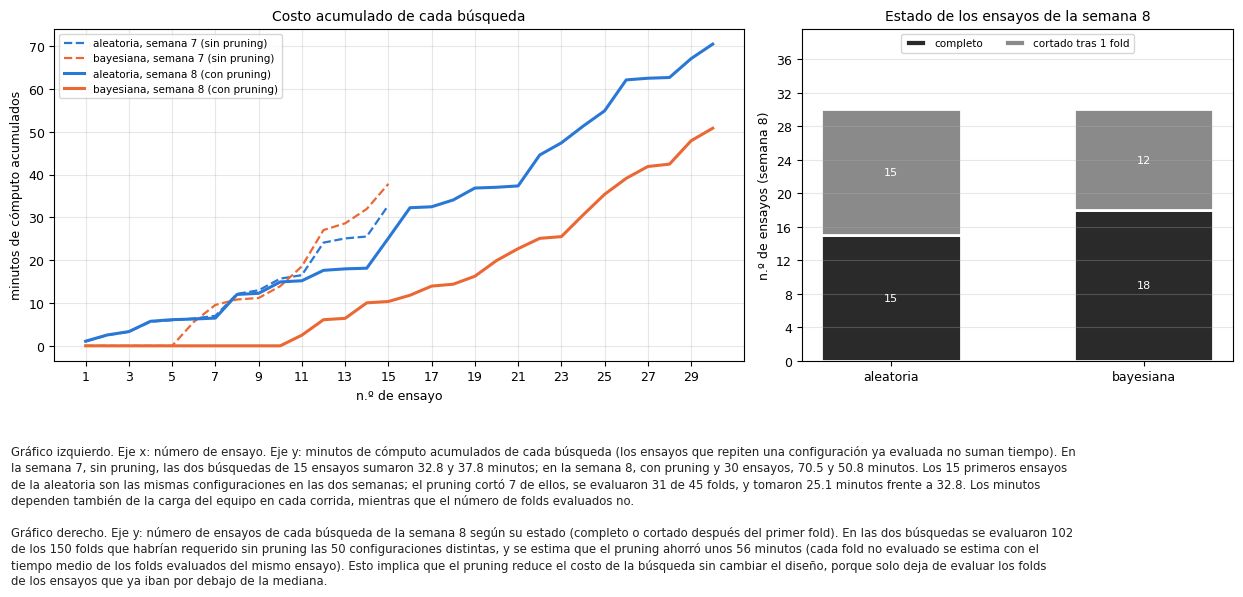

In [7]:
fig = fhp.fig_costo(R, ens, s7); plt.show()

Fuente: elaboración propia a partir de `reportes/hp_pruning_ensayos.csv` y `reportes/hp_ensayos.csv`.

Tabla 4. Ensayos, *folds* y minutos de las búsquedas sin *pruning* (semana 7) y con *pruning* (semana 8)

| Indicador | Semana 7 | Semana 8 |
|---|---|---|
| Ensayos por método (aleatoria / bayesiana) | 15 / 15 | 30 / 30 |
| Ensayos cortados por el *pruning* o por tiempo (aleatoria / bayesiana) | 0 / 0 | 15 / 12 |
| Configuraciones distintas evaluadas | 25 | 50 |
| *Folds* evaluados en esas configuraciones | 75 | 102 de 150 |
| Minutos de cómputo de la búsqueda | 70.6 | 121.3 |
| Mismos 15 ensayos de la aleatoria: *folds* evaluados | 45 | 31 |
| Mismos 15 ensayos de la aleatoria: minutos | 32.8 | 25.1 |
| Mejor PR-AUC media de un ensayo completo (3 *folds*) | 0.8480 | 0.8515 |

Fuente: elaboración propia a partir de `reportes/hp_pruning_resultados.json` y `reportes/hp_ensayos.csv`. Los 70.6 minutos de la semana 7 suman solo sus 25 configuraciones distintas, mientras que los 73.2 que informa para la búsqueda la sección de la semana 7 del README incluyen además la evaluación de la configuración actual en los 3 *folds* (2.6 minutos).

Como se aprecia en la Figura 2 y en la Tabla 4, se cortaron 15 de 30 ensayos de la aleatoria y 12 de 30 de la bayesiana, todos por el *pruning*. En las dos búsquedas se evaluaron 102 de los
150 *folds* que habrían requerido sin *pruning* las 50 configuraciones distintas. Con
ello se estima un ahorro de unos 56 minutos, para lo cual cada *fold* no evaluado se valoró con el tiempo medio
de los *folds* evaluados del mismo ensayo.

Sobre los mismos 15 ensayos de la aleatoria, el *pruning* evaluó 31 de 45 *folds*
y no cortó ninguno de los cinco que fueron los mejores en la semana 7.
El mejor de esa búsqueda en la semana 7, el ensayo 4, quedó completo en la semana 8. Los
minutos dependen también de la carga del equipo en cada corrida, mientras que el número de *folds* evaluados no, por lo que este último es la
medida más estable del ahorro.

In [8]:
print("Estados por búsqueda:", R["estados_por_busqueda"])
print("Ahorro estimado:", R["ahorro_pruning"])
print("Mismos ensayos que la semana 7:", R["efecto_pruning_mismos_ensayos"])
print("Iteraciones de la regresión (máximo por ensayo):", ens.n_iter_max.describe()[["min", "50%", "max"]].to_dict(),
      "· todos convergieron:", bool(ens.convergio.all()))

Estados por búsqueda: {'aleatoria': {'COMPLETE': 15, 'PRUNED': 15}, 'bayesiana': {'COMPLETE': 18, 'PRUNED': 12}}
Ahorro estimado: {'configuraciones_evaluadas': 50, 'folds_evaluados': 102, 'folds_sin_pruning': 150, 'segundos_calculados': 7277.0, 'segundos_ahorrados_estimados': 3359.4}
Mismos ensayos que la semana 7: {'mismas_configuraciones_que_la_semana_7': True, 'n_ensayos': 15, 'cortados': 7, 'folds_evaluados': 31, 'folds_sin_pruning': 45, 'segundos_semana7': 1969.6, 'segundos_semana8': 1508.2, 'dif_maxima_pr_auc_por_fold': 0.0, 'reproduce_folds': True, 'top5_semana7_cortados': [], 'mejor_semana7': 4, 'mejor_semana7_estado_en_semana8': 'completo'}
Iteraciones de la regresión (máximo por ensayo): {'min': 5.0, '50%': 19.5, 'max': 53.0} · todos convergieron: True


Como pide la lámina 15, se registra el número de iteraciones de la regresión (liblinear) en cada *fold*, y la columna `n_iter_max` de
`reportes/hp_pruning_ensayos.csv` y de `logs/hpo_runs.csv` guarda el máximo de cada ensayo. Como se aprecia en la salida anterior, ese máximo
estuvo entre 5 y 53 iteraciones, frente al tope de 2 000 que fija `src/features.py`, y
todos los ajustes de la búsqueda convergieron.

## 6. Importancia de los hiperparámetros

La lámina 20 pide acompañar el gráfico de evolución con la importancia de los hiperparámetros. Se usó el evaluador por defecto de Optuna
5.0.0, es decir, PED-ANOVA (Watanabe et al., 2023), el cual compara la distribución de cada hiperparámetro en los mejores ensayos con
su distribución en todos los ensayos. Se aplicó a las 43 configuraciones completas y distintas de las cuatro
búsquedas, con un cuantil objetivo de 0.116, ajustado para dejar 5 configuraciones sobre él, dado que la documentación de Optuna recomienda al menos 5 (Optuna, s. f.-b).

Figura 3. Importancia de los hiperparámetros

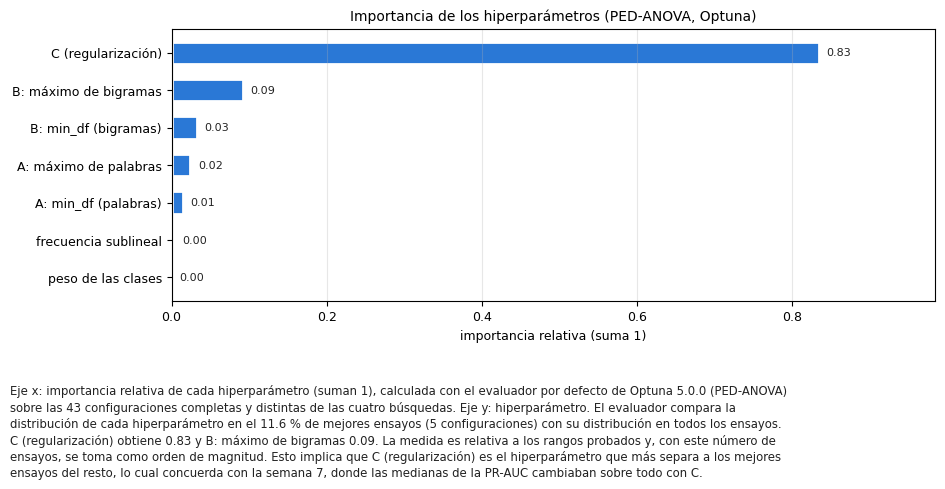

In [9]:
fig = fhp.fig_importancia(R); plt.show()

Fuente: elaboración propia a partir de `reportes/hp_pruning_resultados.json`.

Como se aprecia en la Figura 3, C obtiene la mayor importancia (0.83), seguido del máximo de bigramas
(0.09). Este resultado concuerda con la semana 7, donde las medianas de la PR-AUC cambiaban sobre todo con C. A criterio del autor, el resultado se toma
como orden de magnitud, porque la medida es relativa a los rangos probados y se apoya en pocas configuraciones.

## 7. Confirmación con los 5 *folds*, decisión y configuraciones de respaldo

La candidata de la semana 8 es la configuración completa con mayor PR-AUC media de las dos búsquedas, es decir, la del ensayo
25 de la bayesiana (C 1.87 · A 60 000/3 · B 40 000/5 · sin pesos · sublinear_tf sí).
Se confirmó frente a la actual con los 5 *folds* del proyecto, los mismos de las semanas 5 a 7, y con ellos
se midieron también las dos configuraciones de respaldo. Al respecto, el respaldo 1 es el ensayo 24 de la búsqueda aleatoria de la semana 8 (C 1.44 · A 60 000/3 · B 20 000/5 · balanced · sublinear_tf no). Asimismo, el respaldo 2 es el ensayo 26 de la búsqueda bayesiana de la semana 8 (C 1.51 · A 10 000/3 · B 40 000/5 · sin pesos · sublinear_tf sí).

Tabla 5. PR-AUC por *fold* de la configuración actual, la candidata y las de respaldo (validación cruzada de 5 *folds*)

| *Fold* | Actual | Candidata | Respaldo 1 | Respaldo 2 |
|---|---|---|---|---|
| 1 | 0.8567 | 0.8587 | 0.8595 | 0.8585 |
| 2 | 0.8527 | 0.8539 | 0.8551 | 0.8535 |
| 3 | 0.8467 | 0.8487 | 0.8472 | 0.8484 |
| 4 | 0.8542 | 0.8548 | 0.8558 | 0.8547 |
| 5 | 0.8566 | 0.8575 | 0.8591 | 0.8576 |
| Media | 0.8534 | 0.8547 | 0.8553 | 0.8545 |

Fuente: elaboración propia a partir de `reportes/hp_pruning_resultados.json`. Las diferencias se calculan con los valores sin redondear.

Como se aprecia en la Tabla 5, la candidata superó a la actual en 5 de 5 *folds*, con una diferencia media de
+0.0014 y una desviación estándar de las diferencias de 0.0006.
Por consiguiente, se cumplen las dos condiciones de la regla y la candidata reemplaza a la actual.

In [10]:
print("Regla:", {k: R["regla"][k] for k in ("folds_mejores", "n_folds", "dif_media", "dif_std", "criterio_folds", "criterio_desviacion", "adopta_candidata")})
print("Decisión:", R["decision"], "· test:", "medido" if R["test"] else "no se midió")
for r in R["respaldo"]:
    c = r["confirmacion_5_folds"]
    print(r["rol"], "·", r["origen"], "· 5 folds:", round(c["pr_auc_media"], 4), "±", round(c["pr_auc_std"], 4),
          "· mejor que la ganadora en", c["folds_mejor_que_la_ganadora"], "de 5 folds · atributos:", r["n_atributos"])

Regla: {'folds_mejores': 5, 'n_folds': 5, 'dif_media': 0.00135, 'dif_std': 0.000648, 'criterio_folds': True, 'criterio_desviacion': True, 'adopta_candidata': True}
Decisión: se adopta la candidata · test: medido
respaldo_1 · semana 8 · aleatoria #24 · 5 folds: 0.8553 ± 0.0049 · mejor que la ganadora en 4 de 5 folds · atributos: 67534
respaldo_2 · semana 8 · bayesiana #26 · 5 folds: 0.8545 ± 0.004 · mejor que la ganadora en 1 de 5 folds · atributos: 50091


Como la regla adoptó la candidata, el *test* se midió para la actual y para la candidata después de aplicar la regla, como se fijó antes
de correr.

Tabla 6. Medición en *test* de la configuración actual y de la candidata

| Configuración | PR-AUC sin etiqueta dudosa | IC 95 % | PR-AUC con todas las epicrisis | ROC-AUC | Sensibilidad | Especificidad | Brier |
|---|---|---|---|---|---|---|---|
| Actual | 0.8671 | 0.8589–0.8749 | 0.8580 | 0.8706 | 0.7689 | 0.8038 | 0.1462 |
| Candidata | 0.8670 | 0.8593–0.8745 | 0.8581 | 0.8699 | 0.7629 | 0.8110 | 0.1464 |

Fuente: elaboración propia a partir de `reportes/hp_pruning_resultados.json`. La sensibilidad y la especificidad usan el umbral de 0.5, y el intervalo de confianza remuestrea pacientes 200 veces. El Brier es el error cuadrático medio de la probabilidad, en las epicrisis sin etiqueta dudosa. El *test* se calculó en la corrida del 2 de noviembre y de nuevo en la retomada, con los mismos valores.

Como se aprecia en la Tabla 6, en *test* la candidata obtuvo una PR-AUC de 0.8670 sin etiqueta dudosa, frente a 0.8671 de la actual, es decir, una diferencia de -0.0001, con intervalos de confianza que se solapan. La configuración actual repite los valores de *test* de la semana 7. A criterio del autor, la mejora de la candidata es consistente entre *folds*, pero su magnitud (+0.0014 en validación cruzada) no se aprecia en *test*, por lo que el cambio de configuración no tiene efecto práctico.

In [11]:
for k, t in R["test"].items():
    print(k, "· sin etiqueta dudosa:", t["comun"], "· con todas las epicrisis:", t["completa"])

actual · sin etiqueta dudosa: {'pr_auc': 0.8671, 'f1': 0.7779, 'recall': 0.7689, 'especificidad': 0.8038, 'roc_auc': 0.8706, 'vpp_prevalencia_real': 0.5989, 'pr_auc_ic95_pacientes': [0.8589, 0.8749], 'brier': 0.1462} · con todas las epicrisis: {'pr_auc': 0.858, 'f1': 0.7584, 'recall': 0.7189, 'especificidad': 0.795, 'roc_auc': 0.8398, 'vpp_prevalencia_real': 0.572, 'pr_auc_ic95_pacientes': [0.8493, 0.8664]}
candidata · sin etiqueta dudosa: {'pr_auc': 0.867, 'f1': 0.7772, 'recall': 0.7629, 'especificidad': 0.811, 'roc_auc': 0.8699, 'vpp_prevalencia_real': 0.606, 'pr_auc_ic95_pacientes': [0.8593, 0.8745], 'brier': 0.1464} · con todas las epicrisis: {'pr_auc': 0.8581, 'f1': 0.7577, 'recall': 0.7138, 'especificidad': 0.803, 'roc_auc': 0.8397, 'vpp_prevalencia_real': 0.5799, 'pr_auc_ic95_pacientes': [0.8489, 0.8664]}


En consecuencia, la configuración ganadora es la candidata (C 1.87 · A 60 000/3 · B 40 000/5 · sin pesos · sublinear_tf sí), con
87 534 atributos en el primer *fold* de la búsqueda. El respaldo 1 supera a la ganadora en la PR-AUC media de 5 *folds* (0.8553 frente a 0.8547) y en 4 de 5 *folds*. Sin embargo, la regla prerregistrada se aplica solo a la candidata, por lo que esa diferencia se informa y no cambia la decisión. Además, aun si se le aplicara la regla, su diferencia media con la ganadora (+0.0006) no supera la desviación estándar de esas diferencias (0.0013), por lo que no cumpliría la segunda condición. En cuanto al tamaño, en ese mismo *fold*, el respaldo 1 usa 67 534 atributos y el respaldo 2 usa 50 091 atributos.
De esta manera, junto con la ganadora quedan elegidas dos configuraciones de respaldo, dentro de las 1 o 2 que pide la lámina 20.

## 8. Curva de aprendizaje y control del sobreajuste

La lámina 16 pide guardar la curva de entrenamiento, y el sílabo pone en la semana 8 el control del sobreajuste (*overfitting*). A criterio del autor, en una regresión logística esa curva corresponde a la
curva de aprendizaje, es decir, a la PR-AUC según el número de filas de entrenamiento. Para ello, se entrenó la configuración ganadora con fracciones de las filas de entrenamiento de cada uno de los 5 *folds* del
proyecto, y se midió la PR-AUC en esas mismas filas y en las epicrisis de validación sin etiqueta dudosa. Las fracciones menores que 1 se
ajustaron con el *pipeline* de `src/features.py` sobre el texto, y la fracción 1 con la caché de conteos, que da las mismas matrices.

Figura 4. Curva de aprendizaje de la configuración ganadora

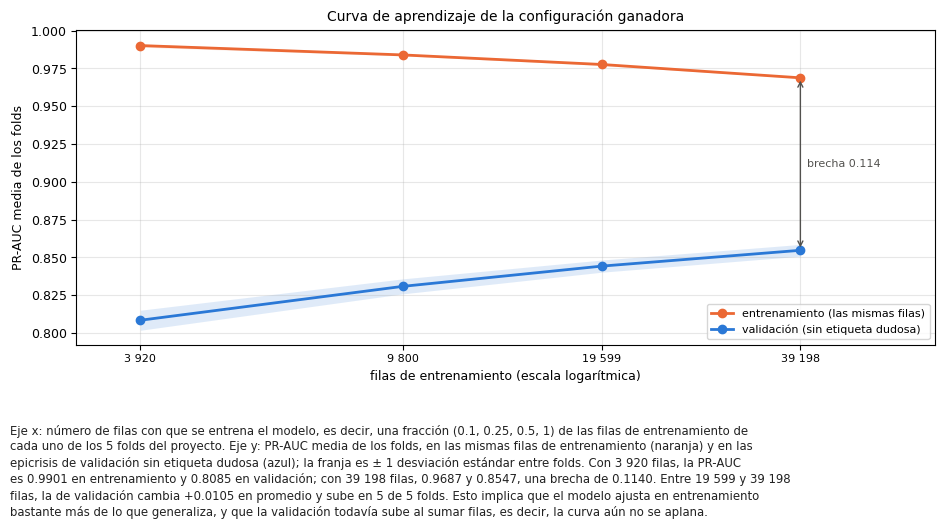

In [12]:
fig = fhp.fig_curva(R, curva); plt.show()

Fuente: elaboración propia a partir de `reportes/hp_pruning_curva.csv`.

Tabla 7. PR-AUC en entrenamiento y en validación según el número de filas de entrenamiento (media de los *folds*)

| Fracción | Filas de entrenamiento | PR-AUC en entrenamiento | PR-AUC en validación (± desv.) | Brecha |
|---|---|---|---|---|
| 0.1 | 3 920 | 0.9901 | 0.8085 ± 0.0066 | 0.1815 |
| 0.25 | 9 800 | 0.9839 | 0.8309 ± 0.0050 | 0.1529 |
| 0.5 | 19 599 | 0.9776 | 0.8443 ± 0.0040 | 0.1333 |
| 1 | 39 198 | 0.9687 | 0.8547 ± 0.0039 | 0.1140 |

Fuente: elaboración propia a partir de `reportes/hp_pruning_curva.csv`. La brecha y las diferencias se calculan con los valores sin redondear.

Como se aprecia en la Figura 4 y en la Tabla 7, con todas las filas la PR-AUC fue 0.9687 en entrenamiento y 0.8547 en validación,
una brecha de 0.1140. Con 3 920 filas, la brecha fue de 0.1815, es decir, la brecha
se reduce al sumar filas. Entre 19 599 y 39 198 filas, la PR-AUC de validación cambió
+0.0105 en promedio y subió en 5 de 5 *folds*. De esta manera, la curva todavía no se aplana. A criterio del autor, mientras eso ocurra, ampliar el número de epicrisis de entrenamiento tiene más recorrido que seguir ajustando hiperparámetros en este espacio. Asimismo, la fracción 1 reproduce la confirmación de la ganadora hasta el sexto decimal, que es el redondeo con el que se guarda la curva.

## 9. Registro de ensayos y artefactos guardados

Todos los ensayos de las semanas 7 y 8 quedaron en un solo registro, `logs/hpo_runs.csv`, con las columnas que pide la lámina 16. Además del
identificador, los parámetros, la semilla, la partición, la media, la desviación y el tiempo, el registro indica si el ensayo usó *pruning*,
cuántos *folds* evaluó, su estado y el número máximo de iteraciones. Como se aprecia en la Tabla 8, la columna de las iteraciones
va vacía en los ensayos de la semana 7, que no las registró, y la desviación va vacía en los ensayos cortados después de un solo *fold*.

Tabla 8. Filas de ejemplo de `logs/hpo_runs.csv`, dos de la semana 7 y dos por cada estado de la semana 8

In [13]:
print(len(runs), "ensayos ·", runs.groupby(["semana", "metodo"]).size().to_dict())
muestra = pd.concat([runs[runs.semana == 7].head(2), runs[runs.semana == 8].groupby("estado", sort=False).head(2)])
m = muestra[["trial_id", "params", "seed", "metric_mean", "metric_std", "folds_evaluados", "estado", "n_iter_max", "tiempo_s"]].copy()
m["metric_std"] = pd.to_numeric(m.metric_std, errors="coerce")
display(m.style.format({"metric_mean": "{:.4f}", "metric_std": "{:.4f}", "tiempo_s": "{:.1f}"}, na_rep="").hide(axis="index"))
print("partición (split_cfg):", runs.split_cfg.iloc[0])

90 ensayos · {(7, 'aleatoria'): 15, (7, 'bayesiana'): 15, (8, 'aleatoria'): 30, (8, 'bayesiana'): 30}


trial_id,params,seed,metric_mean,metric_std,folds_evaluados,estado,n_iter_max,tiempo_s
s7-aleatoria-01,C=0.07459 · A 10000/5 · B 20000/2 · class_weight=ninguno · sublinear_tf=False,42,0.8158,0.0015,3,completo,,62.3
s7-aleatoria-02,C=0.1445 · A 20000/5 · B 40000/3 · class_weight=ninguno · sublinear_tf=True,42,0.8288,0.0008,3,completo,,87.0
s8-aleatoria-01,C=0.07459 · A 10000/5 · B 20000/2 · class_weight=ninguno · sublinear_tf=False,42,0.8158,0.0015,3,completo,11,64.8
s8-aleatoria-02,C=0.1445 · A 20000/5 · B 40000/3 · class_weight=ninguno · sublinear_tf=True,42,0.8288,0.0008,3,completo,15,87.2
s8-aleatoria-06,C=0.003963 · A 60000/3 · B 20000/2 · class_weight=balanced · sublinear_tf=False,42,0.7712,,1,cortado por pruning,5,9.0
s8-aleatoria-07,C=0.01393 · A 60000/5 · B 40000/5 · class_weight=balanced · sublinear_tf=False,42,0.7858,,1,cortado por pruning,7,13.1


partición (split_cfg): StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42) por subject_id en train; entrenan las filas de D2; métrica en la validación sin etiqueta dudosa


Fuente: elaboración propia a partir de `logs/hpo_runs.csv`.

La ganadora y las de respaldo se reentrenaron con el *pipeline* de `src/features.py` en todas las filas de entrenamiento de D2 y se guardaron con
`joblib`. Como se aprecia en la Tabla 9, cada archivo lleva su huella SHA-256 y, en 2 000 filas de entrenamiento, dio las mismas
probabilidades que el modelo evaluado con la caché de conteos.

Tabla 9. Modelos guardados (fuera de git)

| Rol | Archivo | MiB | SHA-256 (inicio) | Probabilidades frente a la caché (diferencia máxima) |
|---|---|---|---|---|
| ganadora | `models/hp_pruning_ganadora.joblib` | 2.0 | `50e5c114f372b503…` | iguales (1.8e-15) |
| respaldo 1 | `models/hp_pruning_respaldo_1.joblib` | 1.5 | `33dd9f129c328a34…` | iguales (1.4e-15) |
| respaldo 2 | `models/hp_pruning_respaldo_2.joblib` | 1.1 | `6b6a0ab09bcf5e94…` | iguales (2.3e-15) |

Fuente: elaboración propia a partir de `reportes/hp_pruning_resultados.json`.

Los modelos no se suben al repositorio, porque su vocabulario sale de las notas de MIMIC-IV y la licencia de PhysioNet no permite publicarlas,
y `.gitignore` excluye los archivos `*.joblib`. Tampoco se guardó el mejor modelo de cada ensayo, como sugiere la lámina 16, dado que serían
decenas de modelos con ese mismo vocabulario. A criterio del autor, el registro de cada ensayo con su configuración, su semilla y su partición
permite reconstruir cualquiera de ellos con el mismo *script*, lo cual cumple el propósito de trazabilidad de la lámina.

Por otra parte, el sílabo pone en la semana 8 un tablero de experimentos junto con el análisis del sobreajuste. A criterio del autor, el
registro, la tabla *top-k* y las figuras de este cuaderno cumplen ese papel en forma estática, sin las herramientas MLflow o W&B que menciona la lámina
16.

## 10. Conclusiones y recomendaciones

Una vez analizados los resultados, se concluye que la búsqueda con *pruning* encontró una configuración que la regla prerregistrada adoptó, con una mejora media de +0.0014 en los 5 *folds*. Sin embargo, en *test* su PR-AUC fue de 0.8670 frente a 0.8671 de la actual, de modo que la mejora no se apreció fuera de la validación cruzada. Como se fijó en la semana 7, el lote de la revisión ciega no se regenera, y HE2 y HE3 se refieren a la configuración con la que se muestreó.

Asimismo, se concluye que el *pruning* redujo el costo sin cambiar el diseño, dado que se evaluaron 102 de
150 *folds* y se estima un ahorro de unos 56 minutos. Por otra parte,
C fue el hiperparámetro de mayor importancia,
y la curva de aprendizaje muestra una brecha de 0.1140 entre entrenamiento y validación con todas las filas.

A criterio del autor, se recomienda mantener la configuración ganadora y no ampliar la búsqueda en este espacio.
Asimismo, se recomienda dar prioridad a ampliar las epicrisis de entrenamiento antes que a nuevas búsquedas, dado que la curva todavía sube.
El siguiente experimento del Sprint 3 es la evaluación por servicio, grupo de edad y decil de largo de la nota frente al modelo de contexto,
junto con la recalibración de las probabilidades a la prevalencia real.

## Cómo reproducir la semana 8

1) Requisitos: los mismos de la semana 7 (el `.env`, `data/processed/dataset.parquet` y las cachés de dominio y de variantes) y la caché de
conteos de `data/interim/cache_hp/`, que arma `python src/experimentos_hp.py --solo-conteos`.

2) Comando único: `python src/experimentos_hp_pruning.py`, que hace las dos búsquedas, la confirmación, el respaldo, la importancia, la curva y
los modelos. Con `--prueba` corre una versión corta en una muestra, escribe sus resultados en `data/interim/prueba_hp_pruning/` y deja
su *log* en `logs/`.

3) Figuras sin entrenar: `python src/figuras_hp_pruning.py`.

4) La corrida guarda cada *fold* de la búsqueda en `data/interim/cache_hp/resultados_semana8.json` y cada confirmación con 5 *folds* en
`data/interim/cache_hp/resultados.json`. Si se interrumpe, al repetir el comando se toman de ahí, con su tiempo original, y se calculan de
nuevo el *test*, la curva y los modelos, como ocurrió con la corrida del 2 de noviembre (sección 3). Para repetir la búsqueda desde cero se
borra el primero.

## Referencias

Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. En
*Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*. https://arxiv.org/abs/1907.10902

Optuna (s. f.-a). *optuna.pruners.MedianPruner*. Documentación de Optuna, versión 5.0.0 (docstring de la librería instalada).

Optuna (s. f.-b). *optuna.importance.PedAnovaImportanceEvaluator* y *get_param_importances*. Documentación de Optuna, versión 5.0.0
(docstring de la librería instalada).

Rodríguez, G. (2026). *Búsqueda de hiperparámetros* [Diapositivas, material de la semana 7]. Curso MIA-14 Trabajo de Investigación II,
Universidad Nacional de Ingeniería.

Watanabe, S., Bansal, A. y Hutter, F. (2023). PED-ANOVA: Efficiently quantifying hyperparameter importance in arbitrary subspaces. En
*Proceedings of the Thirty-Second International Joint Conference on Artificial Intelligence (IJCAI 2023)*. https://arxiv.org/abs/2304.10255